In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.io as sio
from scipy.optimize import least_squares
from scipy.special import modstruve
from scipy.special import kv
from scipy.io import loadmat
from scipy.stats import norm
from scipy.stats import t

In [2]:
''' Helper function to load the data we care about. '''
def load_mat_file(filename):
    # Load the MATLAB file.
    data = sio.loadmat(filename, squeeze_me=True, struct_as_record=False)
    results = data['results']
    results = results.flatten()
    
    # The main data we care about, for now, are...
    #         w_slit: the slit width, read from the micrometer.
    #   w_excitation: the excitation width, extracted from the image. This is correlated with 'w_slit'.
    #              y: the center-to-center distance between the slit and a pattern. 1x4 array.
    # pattern_signal: the signal measured from the pattern. 1x4 array.
    #  pattern_error: the error in 'pattern_signal'. 1x4 array.
    
    # Preallocate arrays.
    w_slit         = np.zeros((len(results), 1))
    w_excitation   = np.zeros((len(results), 1))
    y              = np.zeros((len(results), 4))
    pattern_signal = np.zeros((len(results), 4))
    pattern_error  = np.zeros((len(results), 4))
    for i, entry in enumerate(results):
        w_slit[i] = entry.w_nominal
        w_excitation[i] = entry.w_measured
        y[i,:] = entry.y_measured
        pattern_signal[i,:] = np.array(entry.pattern_signal)
        pattern_error[i,:] = np.array(entry.pattern_error)
    
    return w_slit, w_excitation, y, pattern_signal, pattern_error

In [3]:
# Now load all the data and concatenate.
# w_slit_1, w_excitation_1, y_1, pattern_signal_1, pattern_error_1 = load_mat_file('analysis_results_1.mat')
# w_slit_2, w_excitation_2, y_2, pattern_signal_2, pattern_error_2 = load_mat_file('analysis_results_2.mat')
# Correction from 10/19/2026.
w_slit_1, w_excitation_1, y_1, pattern_signal_1, pattern_error_1 = load_mat_file('analysis_results_10-19-2026.mat')
w_slit_2, w_excitation_2, y_2, pattern_signal_2, pattern_error_2 = load_mat_file('analysis_results_fine_10-19-2026.mat')

w_slit         = np.concatenate((w_slit_1, w_slit_2), axis=0)
w_excitation   = np.concatenate((w_excitation_1, w_excitation_2), axis=0)
y              = np.concatenate((y_1, y_2), axis=0)
pattern_signal = np.concatenate((pattern_signal_1, pattern_signal_2), axis=0)
pattern_error  = np.concatenate((pattern_error_1, pattern_error_2), axis=0)

# Convert w to a (to be discussed).
a_slit = w_slit/2
a_excitation = w_excitation/2

# Convert y to units of inches (or you can convert a_slit to units of microns).
y_µm = y
y_in = y_µm/(25.4*1e3)

# Normalize the data.
pattern_signal_normalized = pattern_signal/np.max(pattern_signal)
pattern_error_normalized = pattern_error/np.max(pattern_signal)

In [4]:
''' Functions that define our model (see text below for details) '''
# First part of the model.
def func(y, a, λ):
    b = (y-a)/λ
    c = (y+a)/λ
    return c*modstruve(-1,c)*kv(0,c) + c*modstruve(0,c)*kv(1,c) - b*modstruve(-1,b)*kv(0,b) - b*modstruve(0,b)*kv(1,b)

# Define the full model function.
def model_func(params, y, a):
    λ = params[0]
    C = params[1]
    return C*func(y, a, λ)

# Define the residuals function for multiple energies.
def residuals(params, I, y, a):
    return I - model_func(params, y, a)

''' Suggested by ChatGPT '''
def model_confidence_band(params, covariance, dof, y, a, confidence_level=0.95):
    # Evaluate the fitted curve.
    model_A = np.asarray(model_func(params, y, a)).ravel()

    # Calculate the gradient with respect to λ and C.
    G = np.empty((model_A.size, 2))

    # Numerical derivative with respect to λ.
    h = np.cbrt(np.finfo(float).eps)*max(abs(params[0]), 1.0)
    p_plus, p_minus = params.copy(), params.copy()
    p_plus[0] += h
    p_minus[0] -= h

    G[:,0] = ((model_func(p_plus, y, a) -
               model_func(p_minus, y, a))/(2*h)).ravel()

    # Analytical derivative with respect to C.
    G[:,1] = np.asarray(func(y, a, params[0])).ravel()

    # Propagate parameter covariance to the fitted curve.
    variance = np.einsum('ij,jk,ik->i', G, covariance, G)
    sigma = np.sqrt(np.maximum(variance, 0))

    # Calculate pointwise 95% confidence limits.
    t_crit = t.ppf(1-(1-confidence_level)/2, dof)

    model_A_lower = model_A - t_crit*sigma
    model_A_upper = model_A + t_crit*sigma

    return model_A, model_A_lower, model_A_upper

**Model:** $A(y,a) = C\left[r_{+}L_{-1}(r_{+})K_{0}(r_{+}) + r_{+}L_{0}(r_{+})K_{+1}(r_{+}) - r_{-}L_{-1}(r_{-})K_{0}(r_{-}) - r_{-}L_{0}(r_{-})K_{+1}(r_{-})\right]$, _where..._

* $y$ is the center-to-center distance between the slit and the pattern;
* $a$ is the slit half-width, meaning $w=2a$;
* $A(y,a)$ is the signal at position $y$ and slit half-width $a$;
* $r_{\pm} = (y \pm a)/\lambda = (y \pm w/2)/\lambda$;
* $\lambda$ is a fitting parameter that can be interpreted as an analog to the attenuation length;
* $K_{n}$ are modified Bessel functions of the second kind; and
* $L_{n}$ are modified Struve functions.

In [5]:
''' Fit the data. '''
# Preallocate arrays.
n_parameters = 2
n_patterns = np.shape(pattern_signal)[1]
parameter_estimates = np.zeros((n_patterns, n_parameters))
parameter_errors = np.zeros((n_patterns, n_parameters))
covariance_matrices = np.zeros((n_patterns, n_parameters, n_parameters))
fit_dofs = np.zeros(n_patterns, dtype=int)

# Run the fit.
for i in range(0, n_patterns):  # Loop through each pattern.
    # We are going to collapse the data on a per-pattern basis.
    A = np.squeeze(pattern_signal_normalized[:,i])
    y_collapsed = np.squeeze(y_in[:,i])
    a_collapsed = np.squeeze(a_slit)

    # Initial guesses.
    wvl = 550e-9/1e-3 # In mm.
    k = 1e-6
    λ_init = wvl/(4*np.pi*k) # Initial guess is attenuation length from Beer-Lambert law.
    C_init = 1.0
    initial_params = np.hstack([λ_init, C_init])

    # Perform the fit.
    result = least_squares(residuals, initial_params, args=(A, y_collapsed, a_collapsed))
    
    # Extract fitted parameters.
    parameter_estimates[i,:] = result.x
    
    # Calculate the Jacobian matrix and the cost.
#     J = result.jac # Jacobian matrix at the solution.
#     cost = result.cost # Sum of squared residuals at the solution.
#     degrees_of_freedom = len(A) - 2 # Number of data points minus number of parameters.

    # Estimate the variance of the residuals.
#     residual_variance = cost/degrees_of_freedom

    # Calculate the covariance matrix for the parameters.
#     covariance_matrix = residual_variance*np.linalg.inv(J.T @ J)

    # Calculate the standard errors (square roots of the diagonal of the covariance matrix).
#     parameter_errors[i,:] = np.sqrt(np.diag(covariance_matrix))
    
    ''' Correction from ChatGPT '''
    J = result.jac
    cost = result.cost
    dof = result.fun.size - result.x.size

    residual_variance = 2*cost/dof
    covariance_matrix = residual_variance*np.linalg.inv(J.T @ J)

    covariance_matrices[i,:,:] = covariance_matrix
    fit_dofs[i] = dof

    parameter_errors[i,:] = np.sqrt(np.diag(covariance_matrix))

In [6]:
# confidence_level = 0.95
# z = norm.ppf(1-(1-confidence_level)/2)  # 1.96 for 95% confidence.

# Calculate upper and lower bounds for each parameter.
# result_upper = parameter_estimates + z*parameter_errors
# result_lower = parameter_estimates - z*parameter_errors

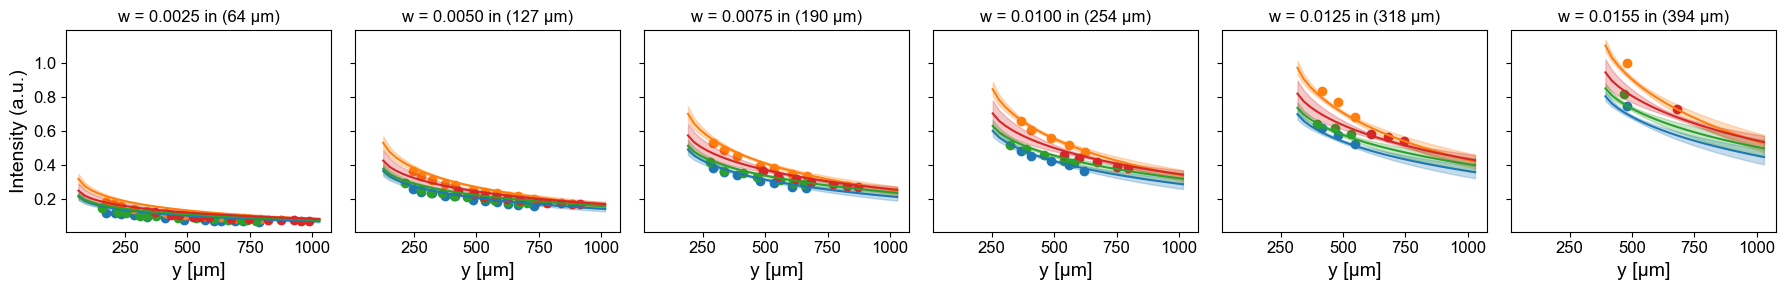

In [7]:
# Set font globally.
plt.rcParams['pdf.fonttype'] = 42  # Type 42 (TrueType), required for Adobe Illustrator.
plt.rcParams['ps.fonttype'] = 42   # Ensures fonts are saved as TrueType in EPS.
plt.rcParams['font.family'] = 'Arial'
params = {'mathtext.default': 'regular' }          
plt.rcParams.update(params)

# Colors corresponding to different patterns.
colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red']

''' We are going to break up the dataset into
    the original two segments: one that showcases
    a- and y-dependence, and one that showcases
    a-dependence over a fine step size. '''
# First: a- and y-depdendent data.
a_fit = np.array([0.005, 0.010, 0.015, 0.020, 0.025, 0.031])/2 # Same as the experimental points.
fig, axes = plt.subplots(1, len(a_fit), figsize=(len(a_fit)*3, 3), sharex=True, sharey=True)
# Loop.
a_index = 0
for ax, current_a_fit in zip(axes, a_fit):
    for j in range(0, n_patterns):
        # Plot the model fit.
        # We add 1e-6 to the left edge of the y-range. This is because the model diverges when y <= a.
        y_fit = np.arange(current_a_fit+1e-6, 0.040+0.001, 0.001)
        model_A, model_A_lower, model_A_upper = model_confidence_band(
            parameter_estimates[j,:],
            covariance_matrices[j,:,:],
            fit_dofs[j],
            y_fit,
            current_a_fit
        )
        ax.plot(y_fit*(25.4*1e3), model_A, color=colors[j])
        ax.fill_between(y_fit*(25.4*1e3), model_A_upper, model_A_lower, color=colors[j], alpha=0.25)
        # Plot the experimental data.
        # The first dataset ends at index 39 (remember Python adds 1 to a colon-separated range).
        indices = np.where(a_slit[0:40] == current_a_fit)
        ax.scatter(y_in[indices[0],j]*(25.4*1e3), pattern_signal_normalized[indices[0],j], color=colors[j])
#         ax.errorbar(y_in[indices[0],j]*(25.4*1e3), pattern_signal_normalized[indices[0],j],
#                     yerr=pattern_error_normalized[indices[0],j],
#                     fmt='o',
#                     ms=4,
#                     color=colors[j],
#                     ecolor=colors[j],
#                     capsize=2)
    
    # Dress up the subplots.
    ax.set_xlabel('y [µm]', fontsize=14)
    if a_index == 0:
        ax.set_ylabel('Intensity (a.u.)', fontsize=14)
    ax.tick_params(axis='x', labelsize=12)
    ax.tick_params(axis='y', labelsize=12)
    ax.set_title('w = {:.4f} in ({:.0f} µm)'.format(current_a_fit, current_a_fit*(25.4*1e3)))
    a_index += 1

plt.tight_layout()
plt.show()

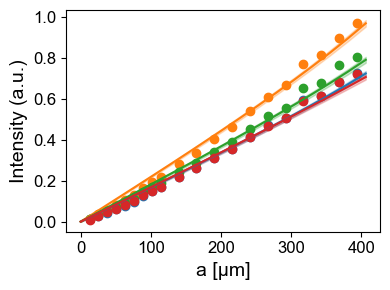

In [8]:
# Set font globally.
plt.rcParams['pdf.fonttype'] = 42  # Type 42 (TrueType), required for Adobe Illustrator.
plt.rcParams['ps.fonttype'] = 42   # Ensures fonts are saved as TrueType in EPS.
plt.rcParams['font.family'] = 'Arial'
params = {'mathtext.default': 'regular' }          
plt.rcParams.update(params)

# Colors corresponding to different patterns.
colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red']

''' We are going to break up the dataset into
    the original two segments: one that showcases
    a- and y-dependence, and one that showcases
    a-dependence over a fine step size. '''
# Second: fine a-depdendent data.
# Get the average y-positions of the patterns (it was fixed during the experiments).
y_fit = np.array([0.005, 0.010, 0.015, 0.020, 0.025, 0.031])/2 # Same as the experimental points.
fig, ax = plt.subplots(1, 1, figsize=(4, 3), sharex=True, sharey=True)
# Loop.
for i in range(0, n_patterns):
    # Plot the model fit.
    # Get the average y-position of the current pattern.
    y_fit = np.mean(np.squeeze(y_in[40:60,i]))
    # We add 1e-6 to the right edge of the y-range. This is because the model diverges when y <= a.
    a_fit = np.arange(0, np.max(a_slit)+0.001, 0.001)
    model_A, model_A_lower, model_A_upper = model_confidence_band(
        parameter_estimates[i,:],
        covariance_matrices[i,:,:],
        fit_dofs[i],
        y_fit,
        a_fit
    )
    ax.plot(a_fit*(25.4*1e3), model_A, color=colors[i])
    ax.fill_between(a_fit*(25.4*1e3), model_A_upper, model_A_lower, color=colors[i], alpha=0.25)
    # Plot the experimental data.
    # The first dataset ends at index 39 (remember Python adds 1 to a colon-separated range).
    ax.scatter(a_slit[40:60]*(25.4*1e3), pattern_signal_normalized[40:60,i], color=colors[i])
#     ax.errorbar(a_slit[40:60]*(25.4*1e3), pattern_signal_normalized[40:60,i],
#                     yerr=pattern_error_normalized[40:60,i],
#                     fmt='o',
#                     ms=4,
#                     color=colors[i],
#                     ecolor=colors[i],
#                     capsize=2)

    # Dress up the subplots.
    ax.set_xlabel('a [µm]', fontsize=14)
    ax.set_ylabel('Intensity (a.u.)', fontsize=14)
    ax.tick_params(axis='x', labelsize=12)
    ax.tick_params(axis='y', labelsize=12)
    ax.grid()

plt.tight_layout()
plt.show()

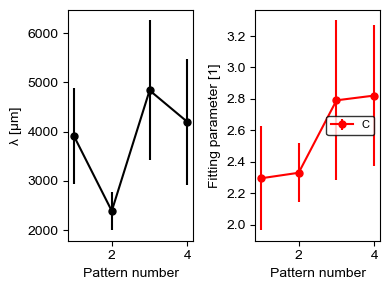

In [9]:
# Plot parameter estimates as a function of energy (with error bars).
fig, axes = plt.subplots(1, 2, sharex=True)

# Plot λ...
ax = axes[0]
ax.errorbar(
    np.arange(1, 4+1), parameter_estimates[:,0] * (25.4*1e3),
    yerr=parameter_errors[:,0] * (25.4*1e3), # Vertical error bars
    marker='o', color='black', markersize=5
    )
ax.set_xlabel('Pattern number')
ax.set_ylabel('λ [µm]')

# Plot C...
ax = axes[1]
ax.errorbar(
    np.arange(1, 4+1), parameter_estimates[:,1],
    yerr=parameter_errors[:,1], # Vertical error bars
    marker='o', color='red', markersize=5, label='C'
    )
ax.set_xlabel('Pattern number')
ax.set_ylabel('Fitting parameter [1]')
ax.legend(loc="center right",  fontsize=8, title_fontsize='small', frameon=True, facecolor='white', edgecolor='black')

# Adjust the size of the figure.
plt.tight_layout()
width, height = fig.get_size_inches()
aspect_ratio = 4/3
new_height = 3
new_width = new_height*aspect_ratio
fig.set_size_inches(new_width, new_height)

plt.tight_layout()
plt.show()

meta NOT subset; don't know how to subset; dropped


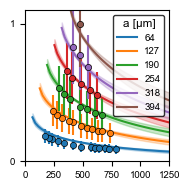

In [10]:
''' PLOT FOR THESIS. '''
# Set font globally.
plt.rcParams['pdf.fonttype'] = 42  # Type 42 (TrueType), required for Adobe Illustrator.
plt.rcParams['ps.fonttype'] = 42   # Ensures fonts are saved as TrueType in EPS.
plt.rcParams['font.family'] = 'Arial'
params = {'mathtext.default': 'regular' }          
plt.rcParams.update(params)

# Colors corresponding to different slit widths.
colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple', 'tab:brown']

# First: a- and y-depdendent data.
a_fit = np.array([0.005, 0.010, 0.015, 0.020, 0.025, 0.031])/2 # Same as the experimental points.
fig, ax = plt.subplots(1, 1, figsize=(2, 2), sharex=True, sharey=True)
# Loop.
# Just plot data for pattern 2. That is the one with the fewest defects.
for i, current_a_fit in enumerate(a_fit):
    # Plot the model fit.
    # We add 1e-6 to the left edge of the y-range. This is because the model diverges when y <= a.
    y_fit = np.arange(current_a_fit+1e-6, 0.060+0.001, 0.001)
    model_A, model_A_lower, model_A_upper = model_confidence_band(
        parameter_estimates[1,:],
        covariance_matrices[1,:,:],
        fit_dofs[1],
        y_fit,
        current_a_fit
    )
    ax.plot(y_fit*(25.4*1e3), model_A, color=colors[i], label=f"{current_a_fit*(25.4*1e3):.0f}")
    ax.fill_between(y_fit*(25.4*1e3), model_A_upper, model_A_lower, color=colors[i], alpha=0.25)
    # Plot the experimental data.
    # The first dataset ends at index 39 (remember Python adds 1 to a colon-separated range).
    indices = np.where(a_slit[0:40] == current_a_fit)
    ax.errorbar(y_in[indices[0],1]*(25.4*1e3), pattern_signal_normalized[indices[0],1],
                yerr=pattern_error_normalized[indices[0],1],
                fmt='none',
                ecolor=colors[i],
                capsize=0)
    ax.scatter(y_in[indices[0],1]*(25.4*1e3), pattern_signal_normalized[indices[0],1], 20,
               facecolor=colors[i], linewidths=0.5, edgecolor='black', zorder=10)
    

# Axis labels.
# ax.set_xlabel('y [µm]', fontsize = 9)
# ax.set_xlabel(None)
# ax.set_ylabel('Intensity (a.u.)', fontsize = 9)
# ax.set_ylabel(None)
plt.xticks(fontsize=7)
plt.yticks(fontsize=7)
ax.set_xlim([0.0, 1250.0])
ax.set_ylim([0.0, 1.1])
ax.set_xticks([0.0, 250.0,  500.0, 750.0, 1000.0, 1250.0])
ax.set_yticks([0.0, 1.0])

# Legend.
ax.legend(loc="upper right",  fontsize=7, title="a [µm]",
          title_fontsize='small', frameon=True, facecolor='white', edgecolor='black')

# Adjust the size of the figure.
plt.tight_layout()
width, height = fig.get_size_inches()
aspect_ratio = 1
new_height = 2
new_width = new_height*aspect_ratio
fig.set_size_inches(new_width, new_height)

# Save with font embedded.
# plt.savefig("data_fit_thesis.pdf", format="pdf", bbox_inches='tight')
# plt.savefig("data_fit.eps", format="eps", bbox_inches='tight')
# plt.savefig("data_fit_CLEO_slides.png", format="png", bbox_inches='tight')

# plt.savefig("fig_3_yagce_uvlaser.pdf", format="pdf", bbox_inches='tight')
plt.savefig("fig_3_yagce_uvlaser_10-19-2026.pdf", format="pdf", bbox_inches='tight') # Corrected version.

plt.show()

In [11]:
parameter_estimates_µm = parameter_estimates[1,:].copy()
parameter_estimates_µm[0] = parameter_estimates_µm[0]*(25.4*1e3)
parameter_errors_µm = parameter_errors[1,:].copy()
parameter_errors_µm[0] = parameter_errors_µm[0]*(25.4*1e3)

In [12]:
print('Parameter estimates:')
print(parameter_estimates_µm)
print('=== === === ===')
print('Parameter errors:')
print(parameter_errors_µm)
print('=== === === ===')

Parameter estimates:
[2.38761006e+03 2.33143291e+00]
=== === === ===
Parameter errors:
[3.92034902e+02 1.87495357e-01]
=== === === ===


In [13]:
# Save fitting parameters.
# np.savez('fitting_parameters_yagce_uvlaser.npz', parameter_estimates_µm, parameter_errors_µm)
np.savez('fitting_parameters_yagce_uvlaser_10-19-2026.npz', parameter_estimates_µm, parameter_errors_µm) # Corrected version.